This notebook is dedicated to exploring our widefield and neuropixel data with PCA.

Suppose we have data $X\in\mathbb{R}^{n\times m}$ with zero mean, where $m$ is the number of features and $n$ is the number of timepoints. PCA finds the directions of maximum variance in the column space of $X$ by finding the eigenvectors and eigenvalues of the covariance matrix $\frac{1}{n}X^TX.$ The eigenvalues are the variances of the data in the direction of the eigenvectors, and the eigenvectors of the covariance matrix are called the principal components.

Given an SVD $X=U\Sigma V^T$, we see that $\frac{1}{n}X^TX=\frac{1}{n}V\Sigma^2 V^T.$ So we see that the variances are just the squares of the singular values of $X$ scaled by $1/n$, and the principal components are just the right singular vectors of $X$.

We start by importing packages.

In [1]:
# Import packages
import numpy as np # Matrix/vector computations
import matplotlib.pylab as plt # Plotting
import pandas as pd # Tables
from tqdm import tqdm # Progress bars
from numpy.linalg import svd, eigh # singular value and (symmetric) eigenvalue decompositions
from sklearn.decomposition import PCA # Automated PCA package
from sklearn.model_selection import train_test_split # For splitting data into training and testing set
from sklearn.preprocessing import StandardScaler # For subtracting out means/optionally normalizing STDs
from sklearn.metrics import explained_variance_score # For computing explained variance 
np.set_printoptions(suppress=True,precision=4) # Make printing more clear
plt.rcParams['figure.dpi']=400 # Increase resolution of figures
plt.rcParams['text.usetex']=True # Use LaTeX in plots

Next we do preprocessing, subtracting out the means of our data and splitting it into train/test sets.

In [2]:
# Load and standardize data

# Neuropixel data
neuropixeldata   = np.load("spikes_v1_clean.npy").T # Load Neuropixel Data
train_np,test_np = train_test_split(neuropixeldata,test_size=0.1,shuffle=False) # Split into train/test set
# We do not shuffle in the train/test split so that the first part of the data predicts the last part
std_neuropixel   = StandardScaler(with_std=False).fit(train_np) # Create StandardScaler
train_np         = std_neuropixel.transform(train_np)
test_np          = std_neuropixel.transform(test_np) # subtract mean of train set from train/test set
num_neurons_np   = neuropixeldata.shape[1] 
num_times        = neuropixeldata.shape[0] # Keep track of number of neurons/timepoints

# Wide field data temporal components
# We will consider the Sigma*V and V cases separately
widefielddata    = np.load("svdTemporalComponents_corr.npy") # Load Widefield data
sigma            = np.linalg.norm(widefielddata,axis=0)
V                = widefielddata / sigma # Separate Sigma*V^T into Sigma and V^T
train_V,test_V   = train_test_split(V,test_size=0.1,shuffle=False)
std_V            = StandardScaler(with_std=False).fit(V) # Get mean
train_V          = std_V.transform(train_V)
test_V           = std_V.transform(test_V) # Subtract mean of train set from train/test set
train_wf,test_wf = train_test_split(widefielddata,test_size=0.1,shuffle=False)
std_wf           = StandardScaler(with_std=False).fit(widefielddata)
train_wf         = std_wf.transform(train_wf)
test_wf          = std_wf.transform(test_wf)

# Create firing rates
num_bins               = num_times-35 # Create bins of width 35
rates                  = np.zeros((num_bins,336))
for i in np.arange(num_bins):
    rates[i]           = np.sum(neuropixeldata[i:i+35,:],axis=0)/35 # Average over sliding time window
train_rates,test_rates = train_test_split(rates,test_size=0.1,shuffle=False)
std_rates              = StandardScaler(with_std=False).fit(rates) # Get mean
train_rates            = std_rates.transform(train_rates)
test_rates             = std_rates.transform(test_rates) # Subtract mean of train set from train/test set

# Save memory by clearing StandardScalers from memory
# as we already have Sigma and V^T and the transformed datasets in their own variables
del std_rates
del std_neuropixel
del std_V

With PCA, it is very easy to compute how much of the variance of a dataset is explained by its first $k$ principal components. Letting $\sigma_j$ denote the $j$th singular value of a data matrix $X$ of rank $n$, the variance explained by the first $k$ principal components is just

$$\frac{\sum_{j=1}^k\sigma_j^2}{\sum_{j=1}^n \sigma_j^2}.$$

In what follows, we will plot the variance explained by the PCA components for each data set as a function of the number of components.

Note: Since PCA was already done on the widefield data, we will not redo PCA on the PCA components, but rather use the PCA components and singular values that we were given.

**To make the plots easier to compare, I have colored the plots magenta up until the point at which 80% of variance in the data is explained, after which the plot becomes orange.**

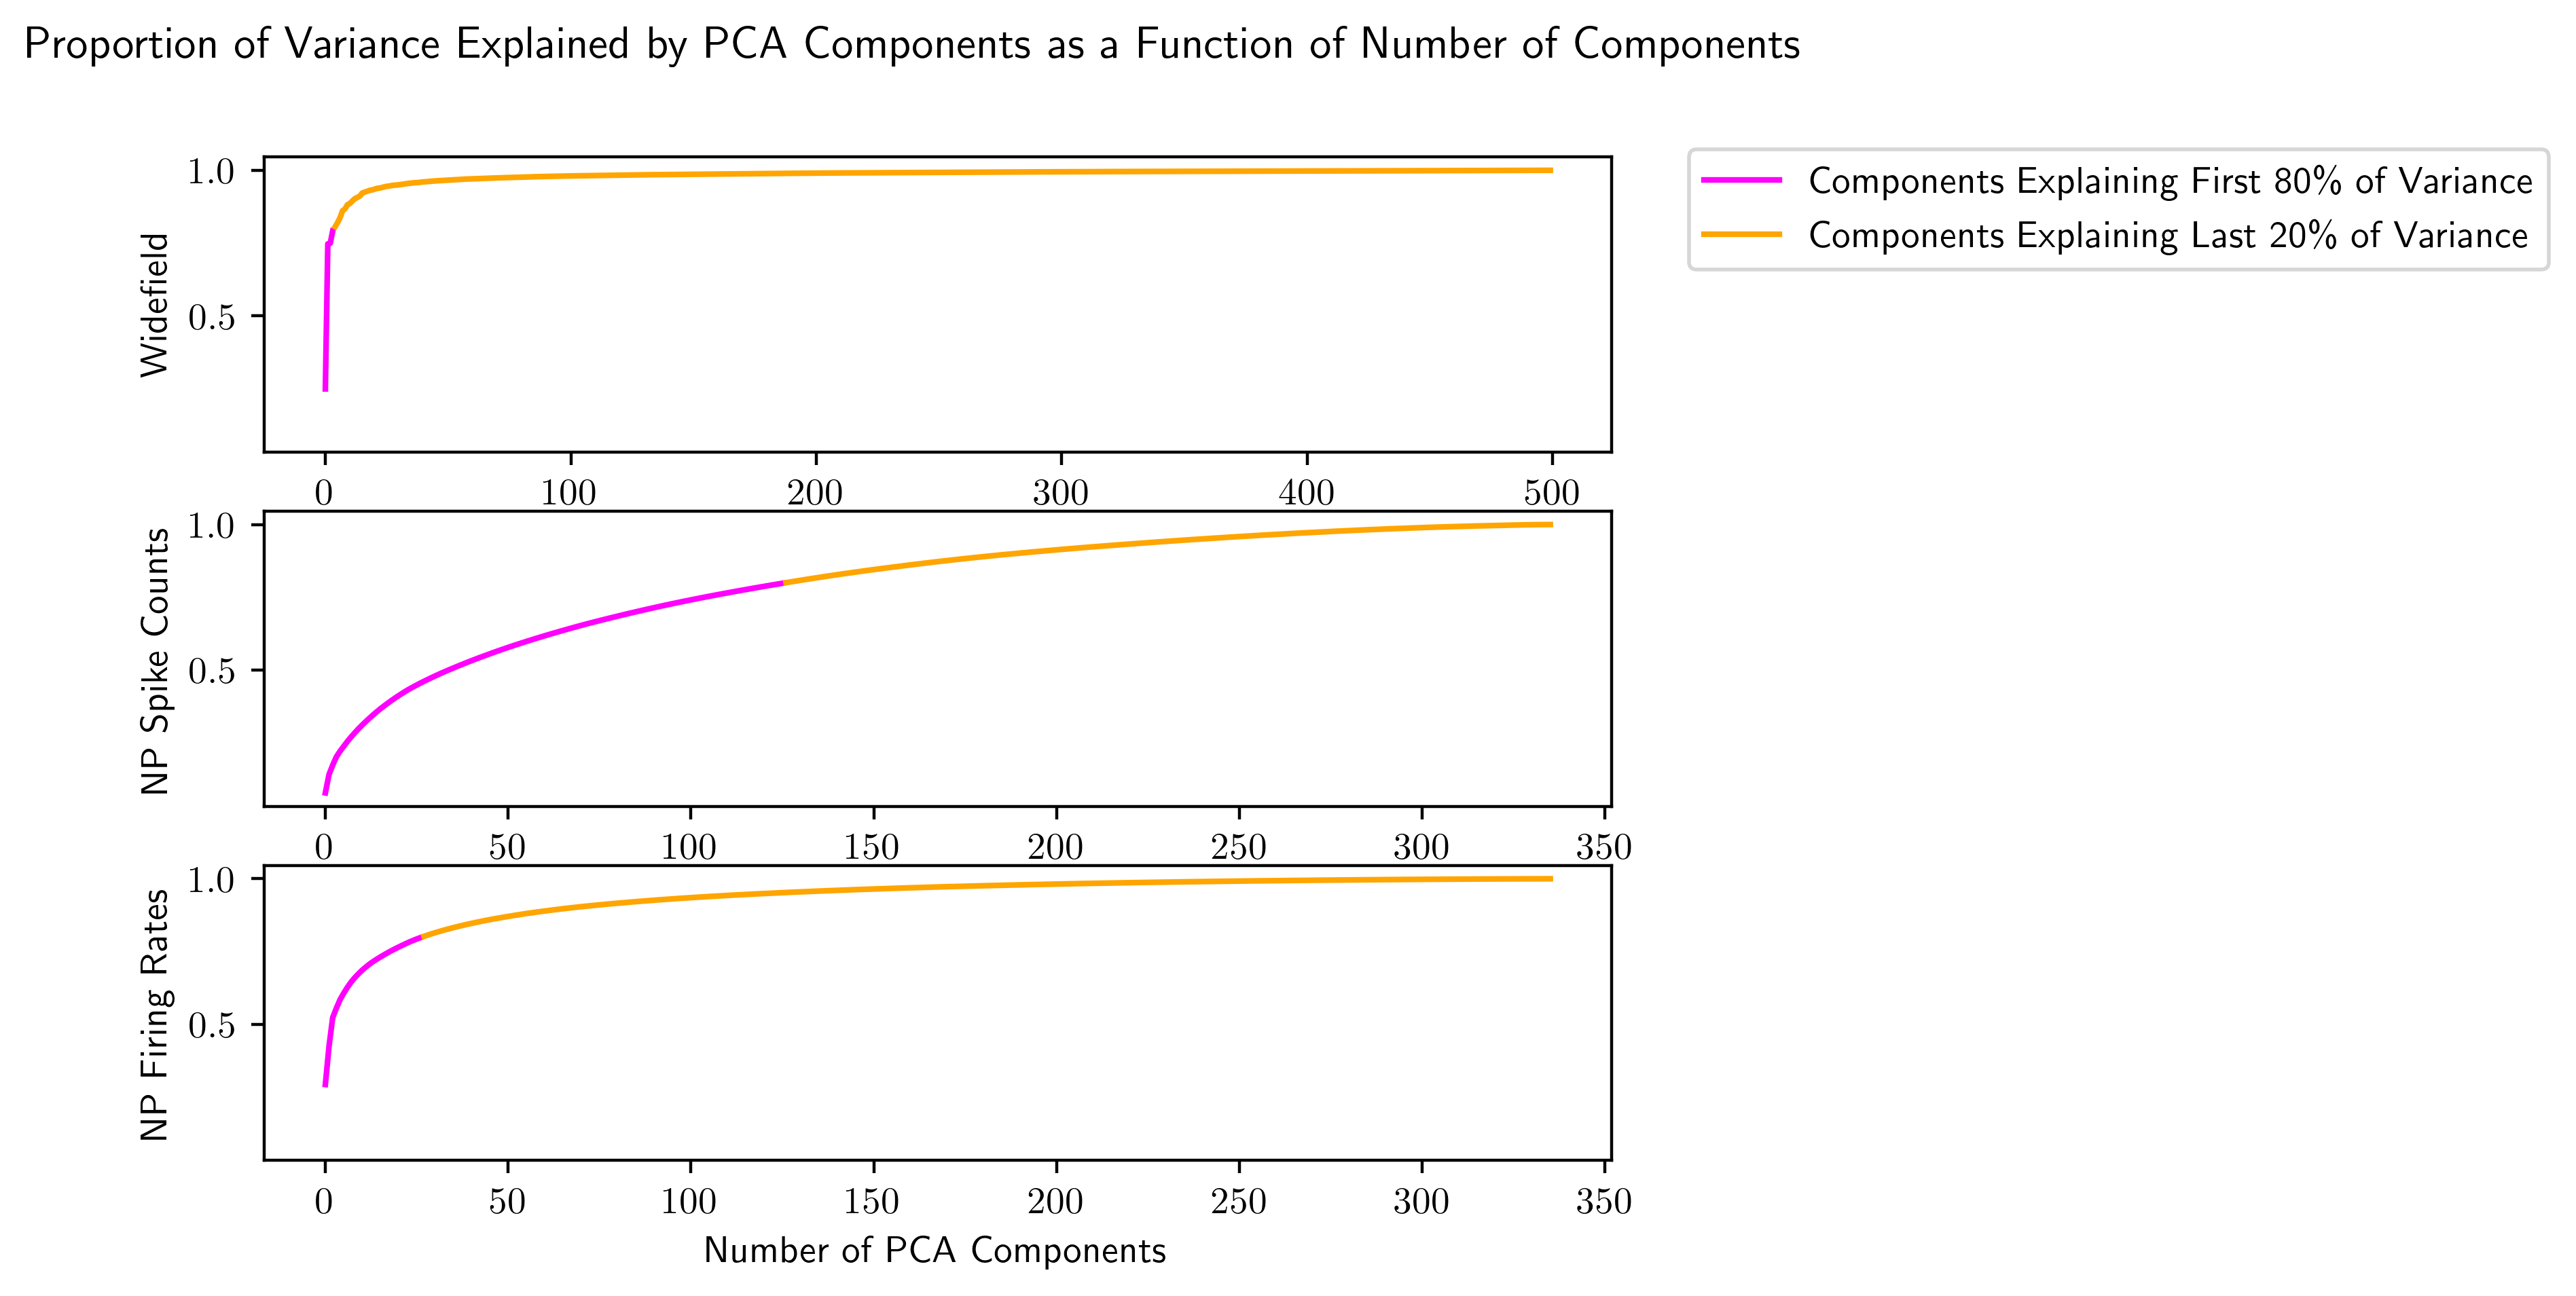

In [3]:
# Do PCA on each data set
# Widefield
wf_explainedvar = np.cumsum(sigma**2)/np.sum(sigma**2)
wf_first_part =  wf_explainedvar[wf_explainedvar<=0.8]
wf_second_part = wf_explainedvar[wf_explainedvar>0.8]

# Neuropixel spike counts
np_pca = PCA().fit(neuropixeldata-np.mean(neuropixeldata,axis=0))
np_explainedvar = np.cumsum(np_pca.explained_variance_ratio_)
np_first_part = np_explainedvar[np_explainedvar<=0.8]
np_second_part = np_explainedvar[np_explainedvar>0.8]

# Neuropixel firing rates
rate_pca = PCA().fit(rates-np.mean(rates,axis=0))
rate_explainedvar = np.cumsum(rate_pca.explained_variance_ratio_)
rate_first_part = rate_explainedvar[rate_explainedvar<=0.8]
rate_second_part = rate_explainedvar[rate_explainedvar>0.8]
# Plot cumulative variance explained as a function of number of PCA components
fig,ax = plt.subplots(3,1,sharey=True)
# Widefield
ax[0].plot(wf_first_part,color='magenta',label="Components Explaining First 80\% of Variance")
ax[0].plot(np.arange(len(wf_second_part))+len(wf_first_part),wf_second_part,color='orange',label="Components Explaining Last 20\% of Variance")
ax[0].set_xlabel("Number of PCA Components")
ax[0].set_ylabel("Widefield")
# Neuropixel spike counts
ax[1].plot(np_first_part,color='magenta')
ax[1].plot(np.arange(len(np_second_part))+len(np_first_part),np_second_part,color='orange')
ax[1].set_xlabel("Number of PCA Components")
ax[1].set_ylabel("NP Spike Counts")
# Neuropixel firing rates
ax[2].plot(rate_first_part,color='magenta')
ax[2].plot(np.arange(len(rate_second_part))+len(rate_first_part),rate_second_part,color='orange')
ax[2].set_xlabel("Number of PCA Components")
ax[2].set_ylabel("NP Firing Rates")
fig.suptitle("Proportion of Variance Explained by PCA Components as a Function of Number of Components");

fig.legend(bbox_to_anchor=(1.45, 0.9));

I interpret these plots as telling us that the widefield data is lower dimensional than the neuropixel data, and that smoothing the neuropixel data with a sliding window reduces its dimensionality (as found by PCA) significantly. However, I wonder if this latter result is related to the highly nonlinear nature of the discrete neuropixel data being harder to represent in a linear basis than the smoothened firing rate data.

The actual number of components needed to explain 80% of the variance in each data set is as follows:

In [6]:
print("Number of Components Needed to Explain 80% of the Variance in Each Data Set:")
print("Widefield: " + str(len(wf_first_part)+1))
print("Neuropixel Spike Counts: " + str(len(np_first_part)+1))
print("Neuropixel Firing Rates: " + str(len(rate_first_part)+1))

Number of Components Needed to Explain 80% of the Variance in Each Data Set:
Widefield: 5
Neuropixel Spike Counts: 127
Neuropixel Firing Rates 28



However, what if we want to compute the amount of variance in dataset $Y$ explained by the variance in the first $k$ principal components of dataset $X$ (assuming datasets $X$ and $Y$ exist in the same space)? In our case, we wish to see how much of the variance in the final part of our data set is explained by the first $k$ principal components of the earlier portion of the dataset.

To do this, we can compute the best approximation of $Y$ in the basis of the first $k$ principal components of $X$. This is precisely the orthogonal projection of $Y$ onto $X$'s principal component subspace, or $YQQ^T$ if $Q$ is the matrix whose columns are the first $k$ principal components of $X$. One way to view this formula is that we change basis by multiplying by $Q$ and then change back to our approximate original basis by multiplying by the pseudoinverse of $Q$, which is just $Q^T$ because $Q$ is orthogonal.

*(Note: I believe this is the standard way to do this with PCA based on this reference: https://stackoverflow.com/questions/57501846/is-there-a-way-to-compute-the-explained-variance-of-pca-on-a-test-set. If it is not, please let me know. A clear limitation with this method is that if $k=\text{rank}(X)$, then $Q^T=Q^{-1}$ because $Q$ will be orthogonal, so $YQQ^T=Y$, and we will compute that the training set explains 100% of the variance in the testing set, regardless of what the training set and testing sets are. Essentially, as I understand it, we are assuming that the test set and training set come from the exact same distribution, so the principal components of the training set are the same as the principal components of the test set. This is presumably false even for our case, but maybe it isn't a bad approximation if all we are looking for is latent stationary structure in our data.)*

Setting $Y_{True}=Y$ and $Y_{Pred}=YQQ^T$, we can compute the variance of $Y$ explained by the first $k$ principal components of $X$ by computing the explained variance score between $Y_{Pred}$ and $Y_{True}$. The explained variance score is similar to the $R^2$ score, but it does not involve subtracting the mean of the error, meaning that it assumes our errors have mean zero rather than being systematically biased, which seems reasonable to me. The mathematical definition of the explained variance score is

$$1-\frac{\text{Var}(Y_{Pred}-Y_{True})}{\text{Var}(Y_{True})},$$
where $\text{Var}$ is the biased variance,
$$\text{Var}(X)=\frac{1}{n}\sum_{i=1}^n(x_i-\bar x)^2.$$

Now, naively if we want to compute the explained variance of $Y$ by the first $k$ components of $X$ as a function of $k$, we would have to compute $YQQ^T$ for many orthogonal projection matrices $QQ^T$. This is extremely slow if $Y$ is large or if we explore large values of $k$. We can do much better in terms of computational complexity by taking $Q$ to be the matrix of right singular vectors corresponding to the maximal rank SVD of interest, and considering the individual projections $YQ[:,k]$ and applying the pseudoinverse $Q^T$ to these, and then calculating the explained variance. This will compute the explained variance of the $k$th component for each $k$ up to the maximum rank of interest.

In [4]:
def predicted_variance(train,test,max_comps):
    model = PCA(n_components=max_comps).fit(train) # Fit PCA
    result = np.zeros(model.n_components)
    test_proj = model.transform(test) # Multiply test by V
    for i in tqdm(range(model.n_components)):
        test_proj_i = np.zeros_like(test_proj)
        test_proj_i[:,i] = test_proj[:,i] # Create matrix whose ith column is (YV)[:,i], zeros elsewhere
        approx = model.inverse_transform(test_proj_i) # Multiply this new matrix by V^T
        result[i] = 1 - (np.linalg.norm(approx-test)/
                         np.linalg.norm(test-model.mean_))**2 # Compute explained variance
    return np.cumsum(result)

First as a sanity check, let's just show that this method reproduces the usual explained variance when the training and test sets are the same.

In [5]:
np_explainedvar_new = predicted_variance(train_np,train_np,100)

100%|█████████████████████████████████████████| 100/100 [01:04<00:00,  1.55it/s]


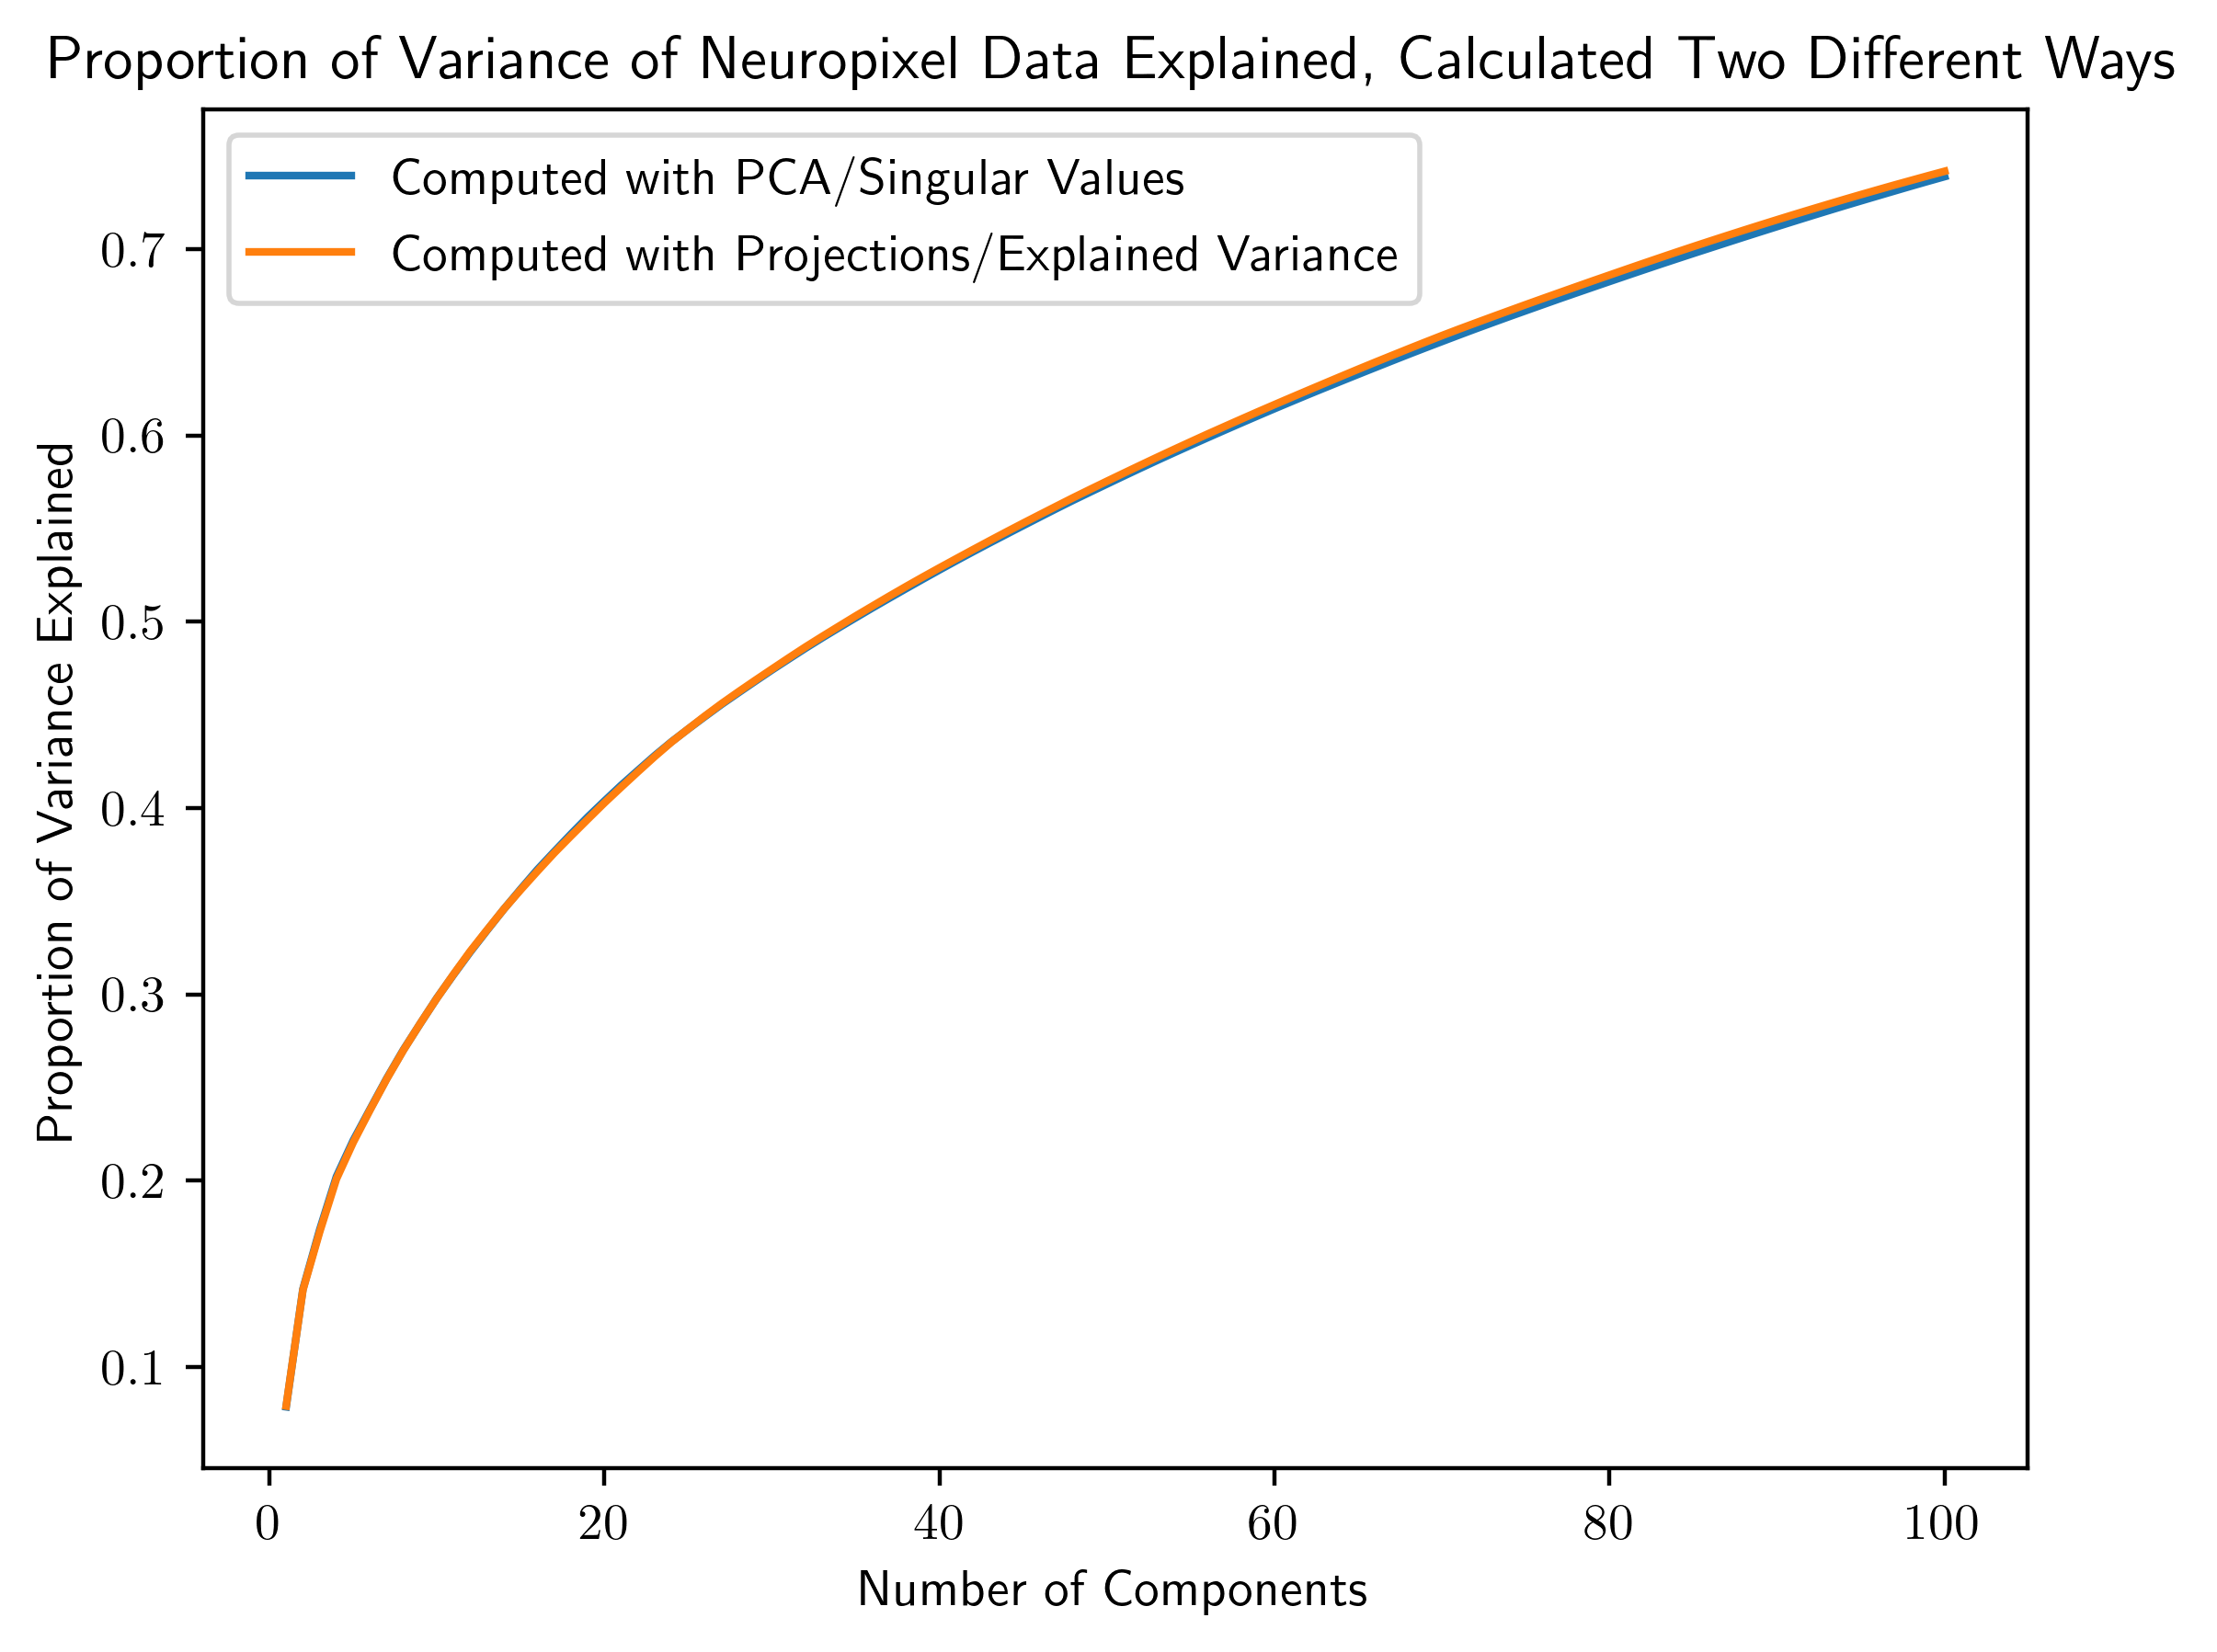

In [6]:
plt.plot(np.arange(1,101),np_explainedvar[:100],label="Computed with PCA/Singular Values")
plt.plot(np.arange(1,101),np_explainedvar_new,label="Computed with Projections/Explained Variance")
plt.xlabel("Number of Components")
plt.ylabel("Proportion of Variance Explained")
plt.title("Proportion of Variance of Neuropixel Data Explained, Calculated Two Different Ways")
plt.legend();

These plots overlap, as we would hope. As another sanity check and relative benchmark, let's see how much of the variance of random noise is explained by the neuropixel data.

In [35]:
np.random.seed(0)
random = np.random.rand(test_np.shape[0],test_np.shape[1])
randomvar_explained = predicted_variance(test_np,random,100)
random_predicting_npvar = predicted_variance(random,test_np,100)

100%|█████████████████████████████████████████| 100/100 [00:03<00:00, 31.71it/s]


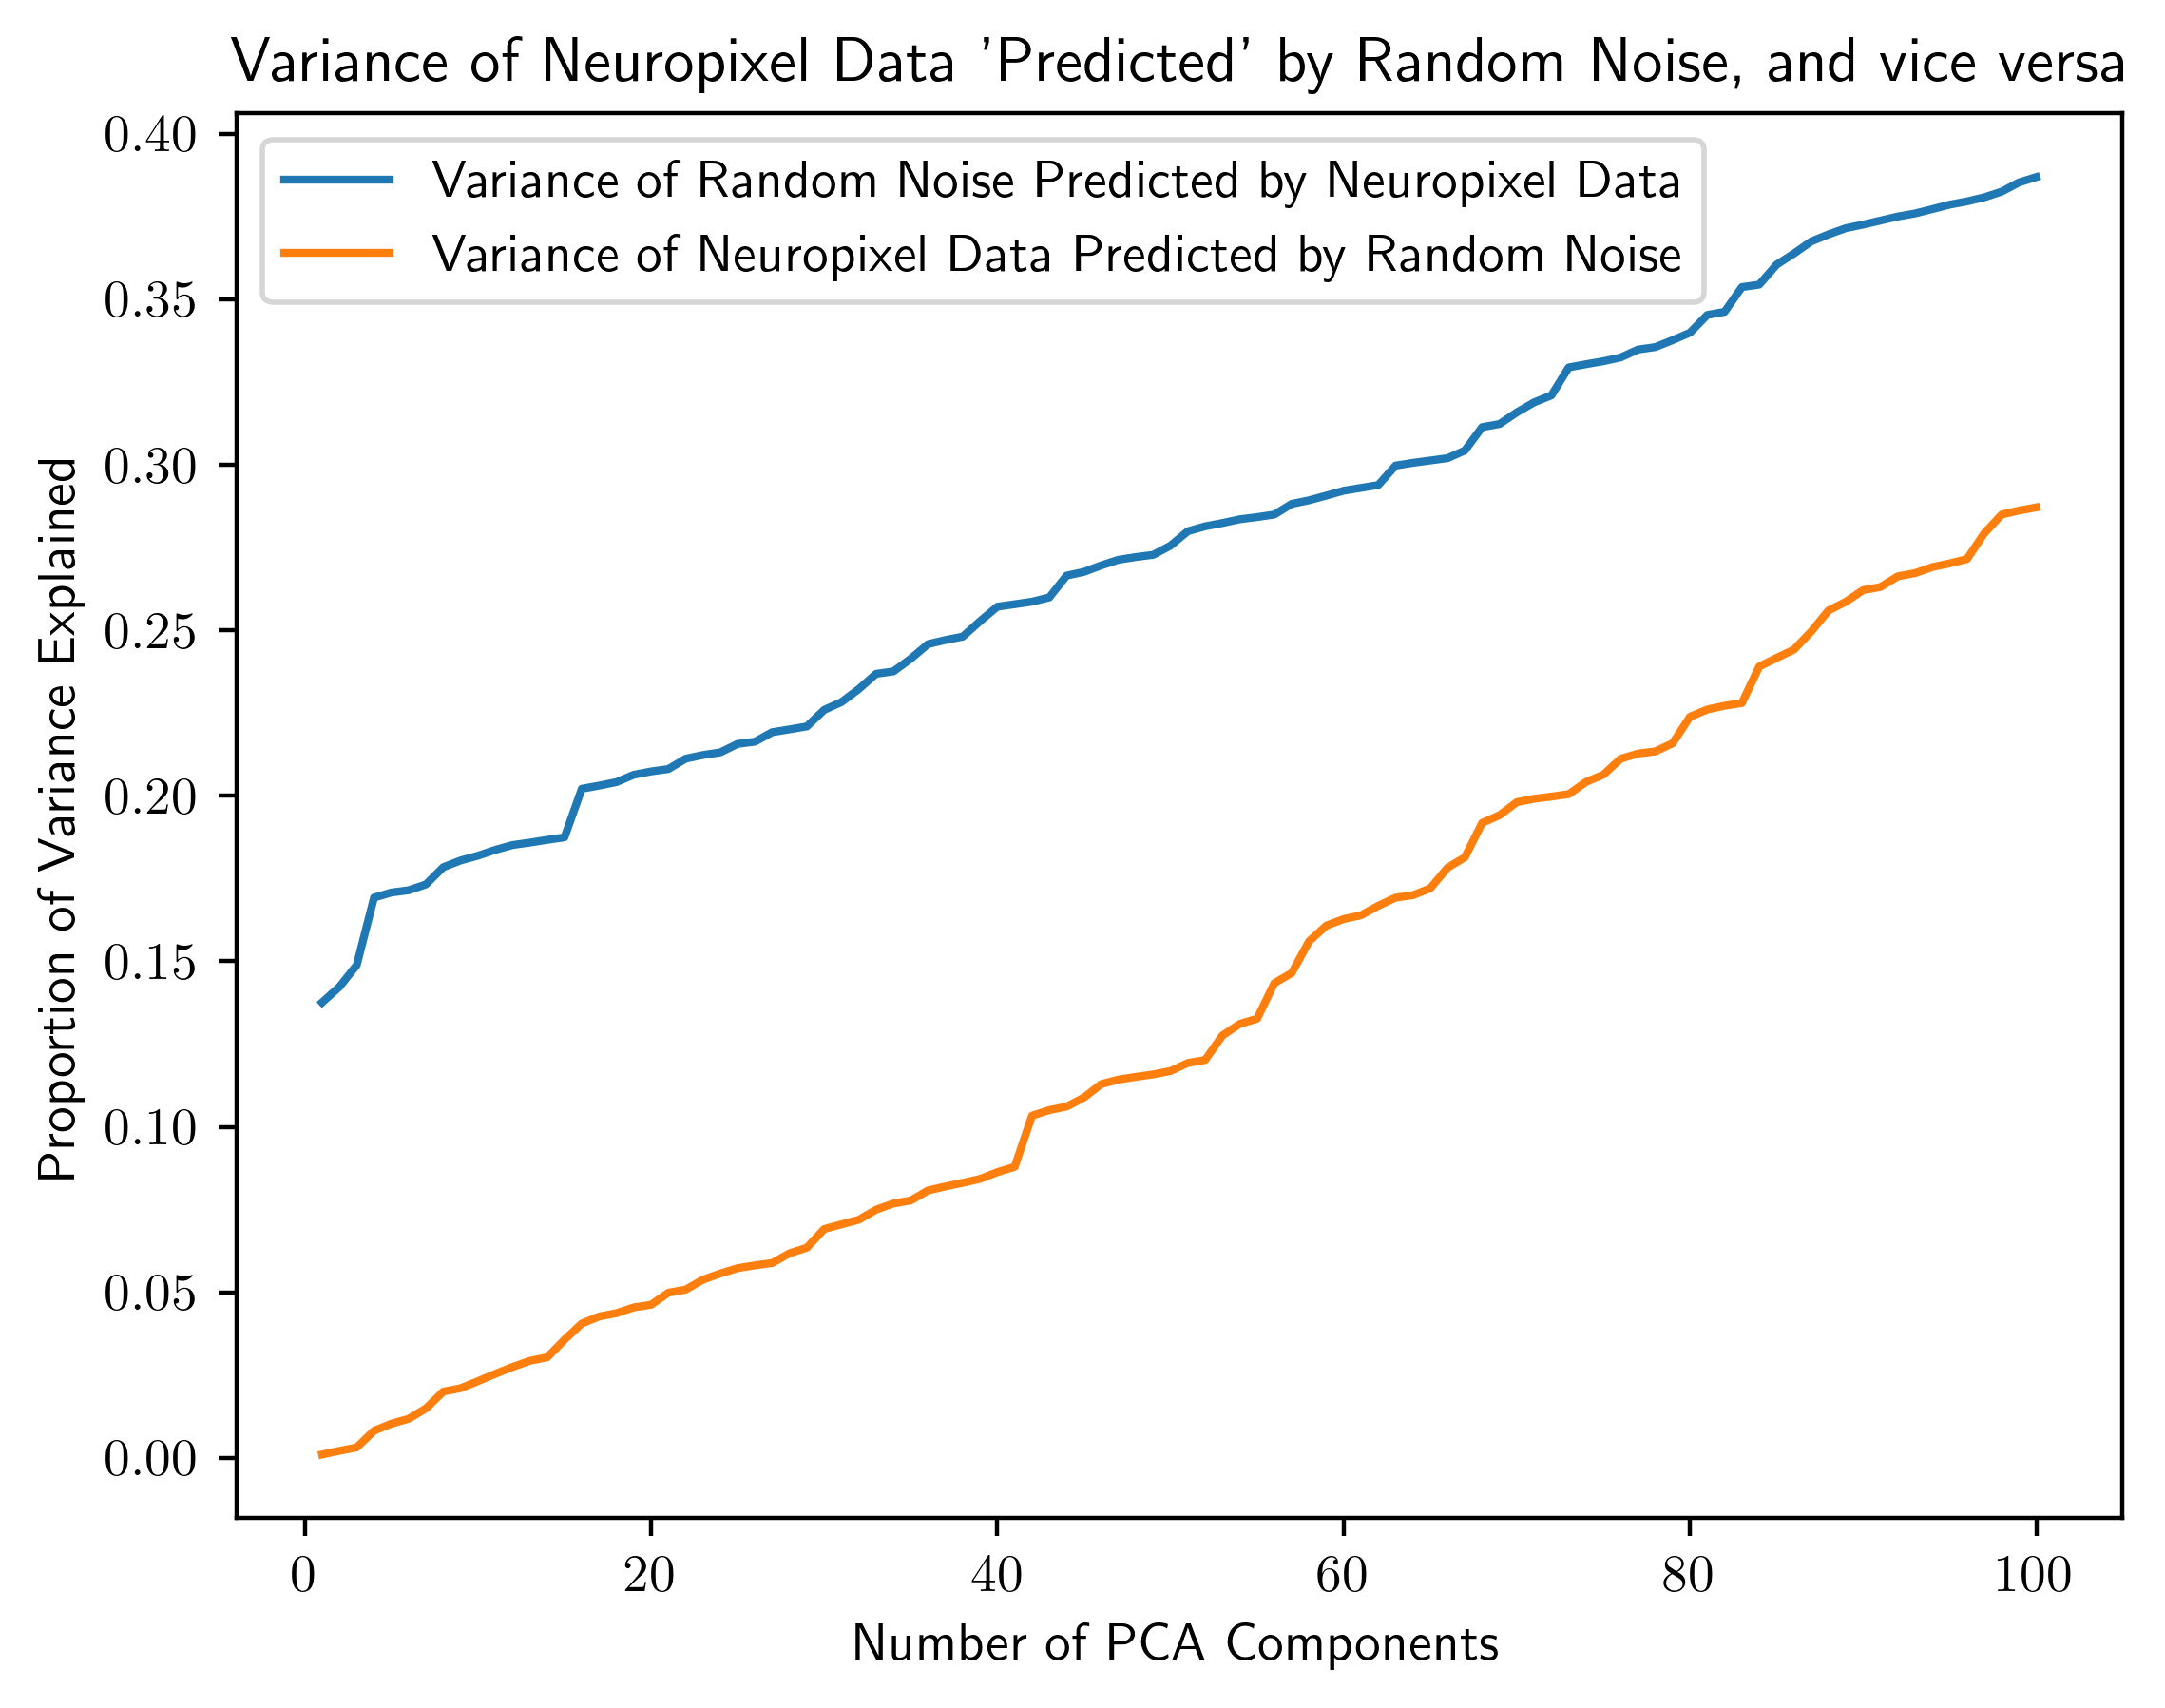

In [39]:
plt.plot(np.arange(1,101),randomvar_explained,label="Variance of Random Noise Predicted by Neuropixel Data")
plt.plot(np.arange(1,101),random_predicting_npvar,label="Variance of Neuropixel Data Predicted by Random Noise")
plt.xlabel("Number of PCA Components")
plt.ylabel("Proportion of Variance Explained")
plt.title("Variance of Neuropixel Data 'Predicted' by Random Noise, and vice versa")
plt.legend();

In both cases, the algorithm is able to fit the noise. I am not sure if this says anything about how much noise is in our data, but clearly we do not want to say that one dataset is explaining the other when training on random noise could have produced the same result with our metric.

An interesting fact though is that in both of these plots, the relationship between proportion of variance explained and the number of PCA components is linear, whereas in our earlier PCA plots, the relationship is initially nonlinear before becoming close to linear. Presumably this linearity is because adding a random PCA component increases overfitting, while adding PCA components that correspond to actual latent variables increase the variance explained by a nonlinear amount. We can quantify this by looking at the second derivatives of our plots (computed with central difference schemes).

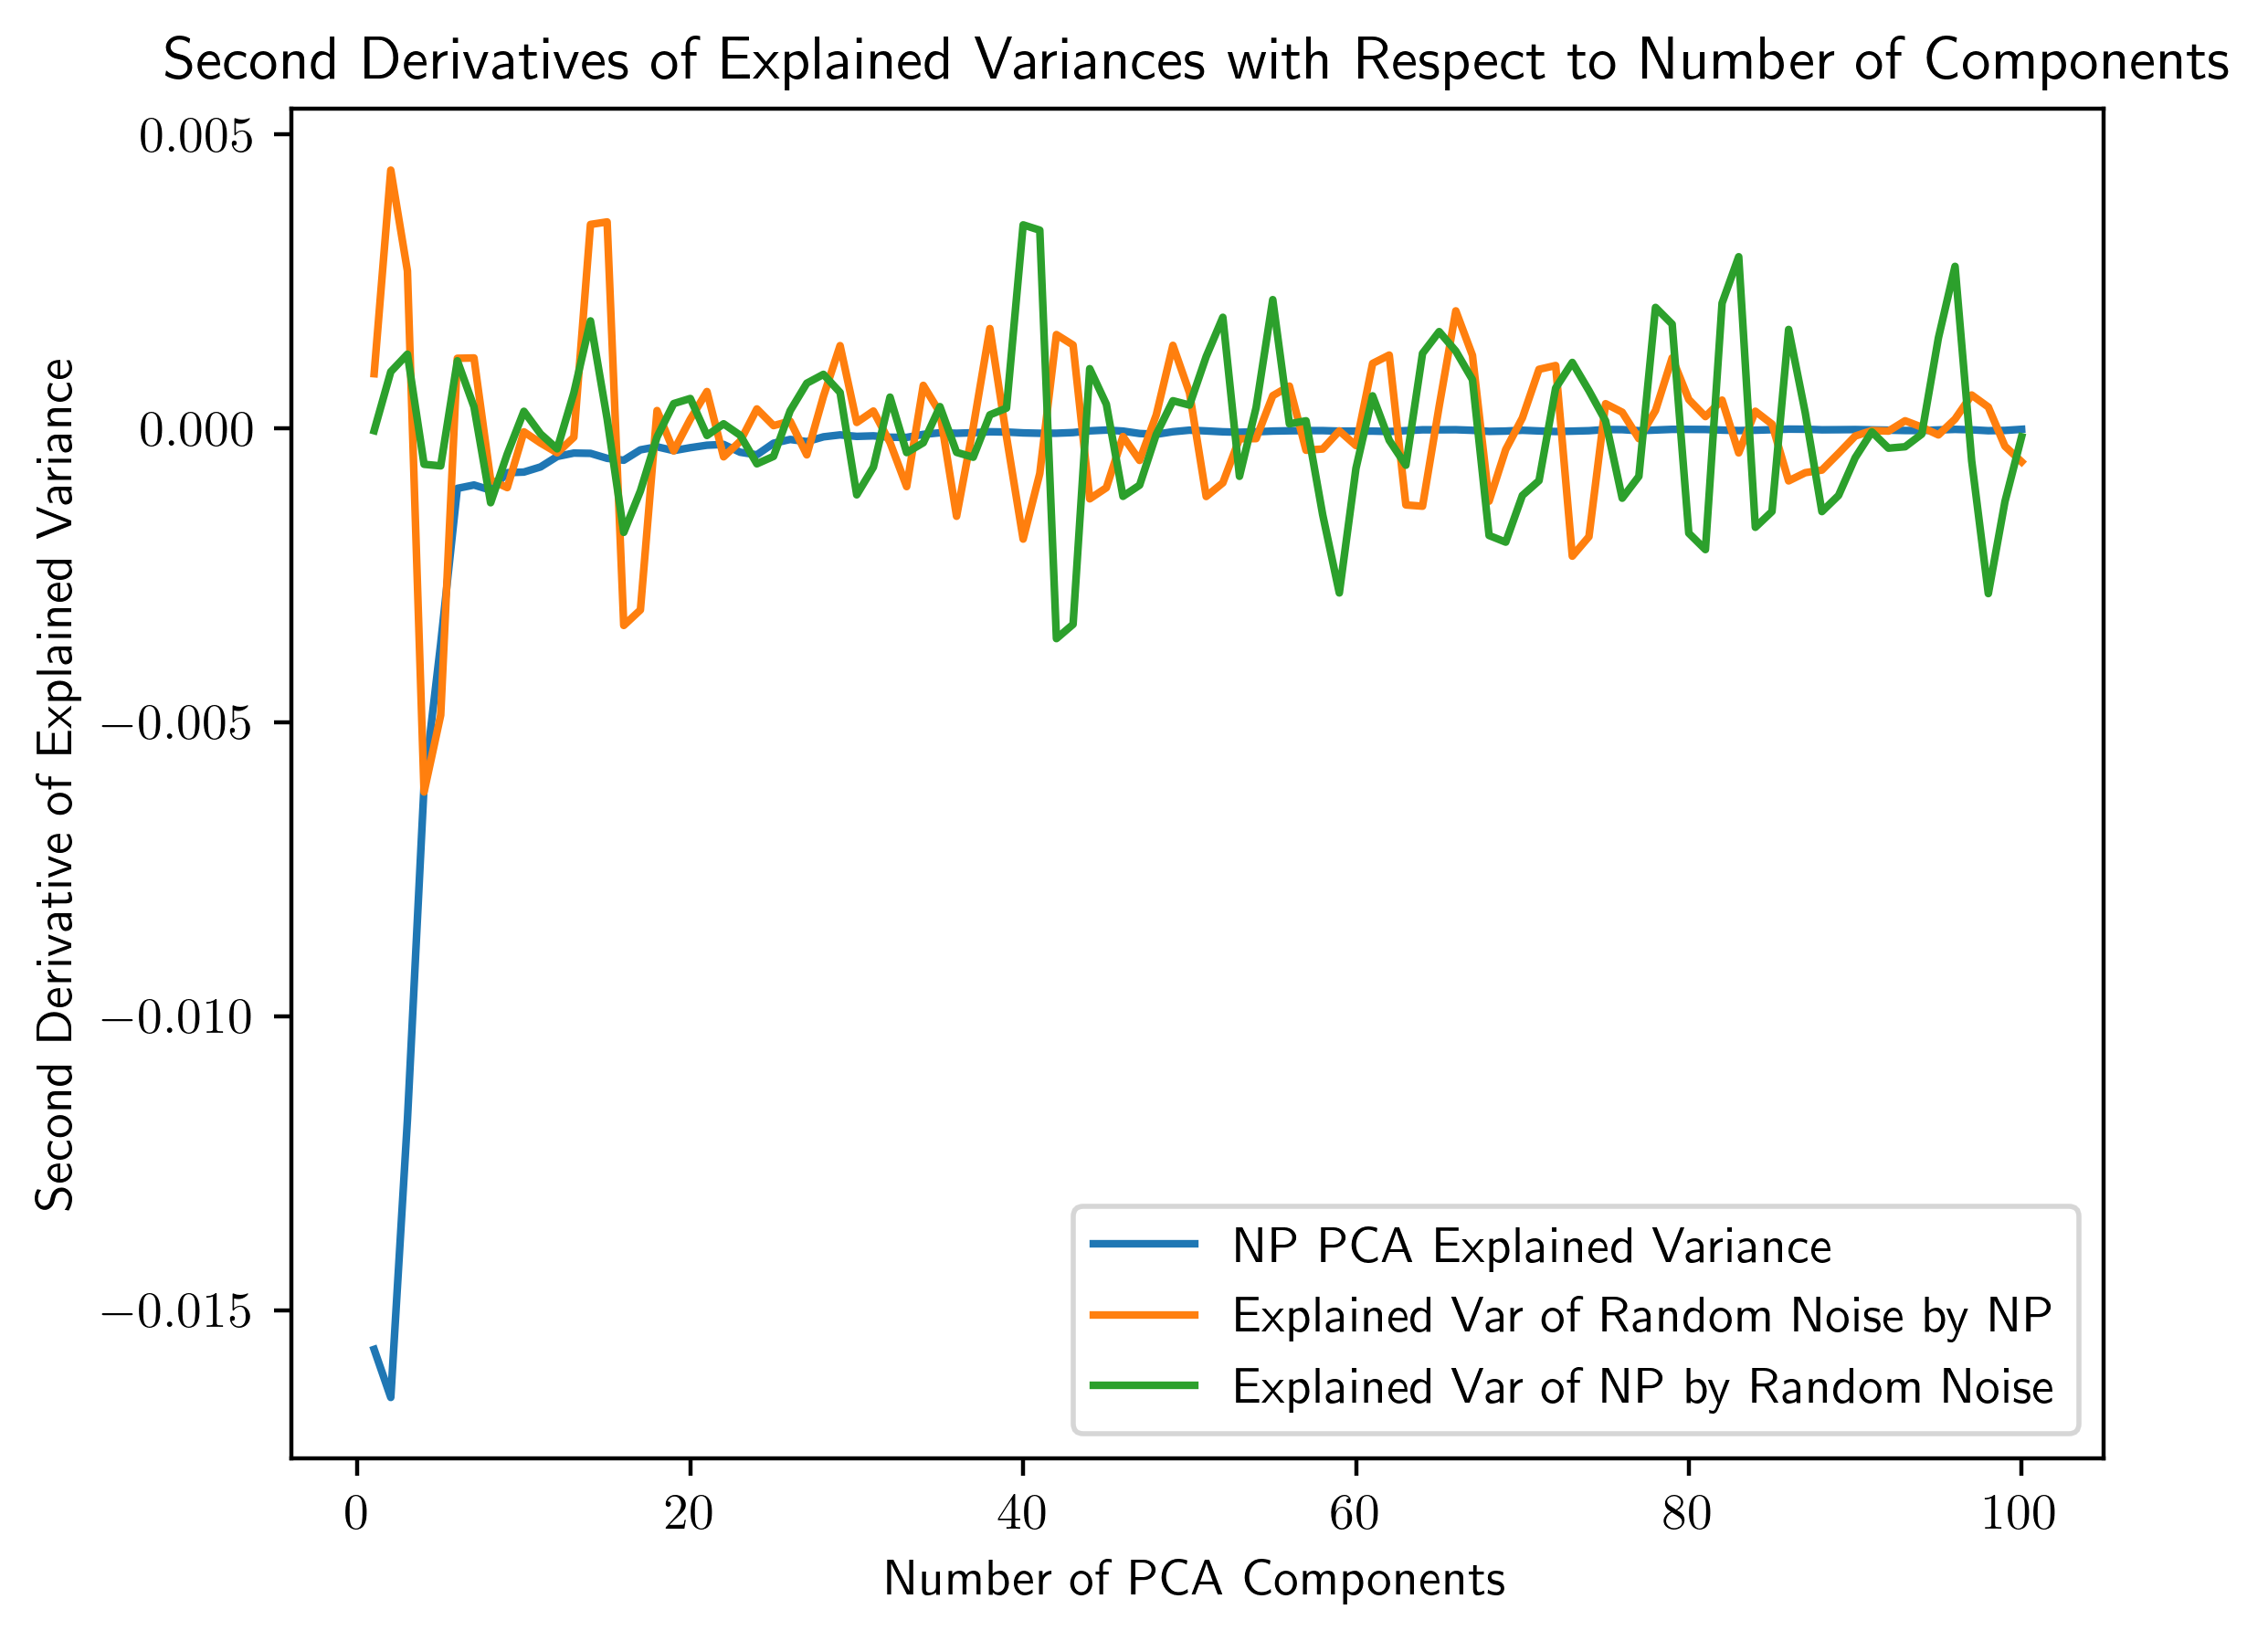

In [59]:
d2dx = lambda x: np.gradient(np.gradient(x))
plt.plot(np.arange(1,101),d2dx(np_explainedvar)[:100],label="NP PCA Explained Variance")
plt.plot(np.arange(1,101),d2dx(randomvar_explained), label="Explained Var of Random Noise by NP")
plt.plot(np.arange(1,101),d2dx(random_predicting_npvar), label="Explained Var of NP by Random Noise")
plt.title("Second Derivatives of Explained Variances with Respect to Number of Components")
plt.xlabel("Number of PCA Components")
plt.ylabel("Second Derivative of Explained Variance")
plt.legend();

To me, this looks very promising. The second derivative of the variance explained by random noise (or variance of random noise explained) as a function of the number of PCA components is clearly mean zero, indicating that it is linear (plus noise). On the other hand, the real data's explained variance has an initially nonzero second derivative which eventually becomes zero. Thus, we can interpret a nonzero second derivative of the explained variance as a function of the number of PCA components as indicating that the PCA component adds more information than random noise would.

As a way to classify the number of latent variables, we can look at when the second derivative of the explained variance as a function of the number of PCA components becomes essentially zero. The following function implements this.

In [89]:
def latent_dim(data,threshold):
    # Compute 2nd derivative
    d2data = d2dx(data)
    # Threshold
    return np.sum(np.abs(d2data)>threshold)

The following code produces a table showing the number of components where the second derivative was above threshold, for four different thresholds (0.005, 0.001, 0.0005, and 0.0001).

In [122]:
latent_dims = pd.DataFrame()
latent_dims['Neuropixel Spike Counts']=[latent_dim(np_explainedvar,0.005),latent_dim(np_explainedvar,0.001),latent_dim(np_explainedvar,0.0005),latent_dim(np_explainedvar,0.0001)]
latent_dims['Widefield (SV)'] = ([latent_dim(wf_explainedvar,0.005),latent_dim(wf_explainedvar,0.001),latent_dim(wf_explainedvar,0.0005),latent_dim(wf_explainedvar,0.0001)])
latent_dims['Neuropixel Firing Rates'] = ([latent_dim(rate_explainedvar,0.005),latent_dim(rate_explainedvar,0.001),latent_dim(rate_explainedvar,0.0005),latent_dim(rate_explainedvar,0.0001)])
latent_dims.index = ['0.005','0.001','0.0005','0.0001']
latent_dims

,Neuropixel Spike Counts,Widefield (SV),Neuropixel Firing Rates
0.005,4,4,4
0.001,7,13,11
0.0005,13,16,14
0.0001,35,34,35


All datasets appear to have four latent variables that explain much more of the variance than any of the other components. There are probably about ten latent variables beyond that which add some information. (Based on the above plot, it looks like components 13-35 may be adding slightly more information than a random PCA component could add, but the effect appears negligible enough to ignore).

Let's explore the predictive abilities of each data set, i.e. the variance of a held-out test set (the last 10% of the data in this case) explained by the first $k$ PCA components of the training set as a function of $k$. For the sake of speed on my slow computer, I will only compute this for up to $k=200.$ For the widefield data, as we are already given an SVD we will not recompute it.

In [7]:
V_scores = predicted_variance(train_V,test_V,200)
wf_scores = predicted_variance(train_wf,test_wf,200)
np_scores = predicted_variance(train_np,test_np,200)
rate_scores = predicted_variance(train_rates,test_rates,200)

100%|█████████████████████████████████████████| 200/200 [00:10<00:00, 19.11it/s]


We will now plot the variance of the test set explained by the first $k$ PCA components of the training set as a function of $k$. Similar to above, for easy visual comparisons I have colored the plots magenta up until the point at which 70% of the variance is explained, at which point the plot becomes orange.

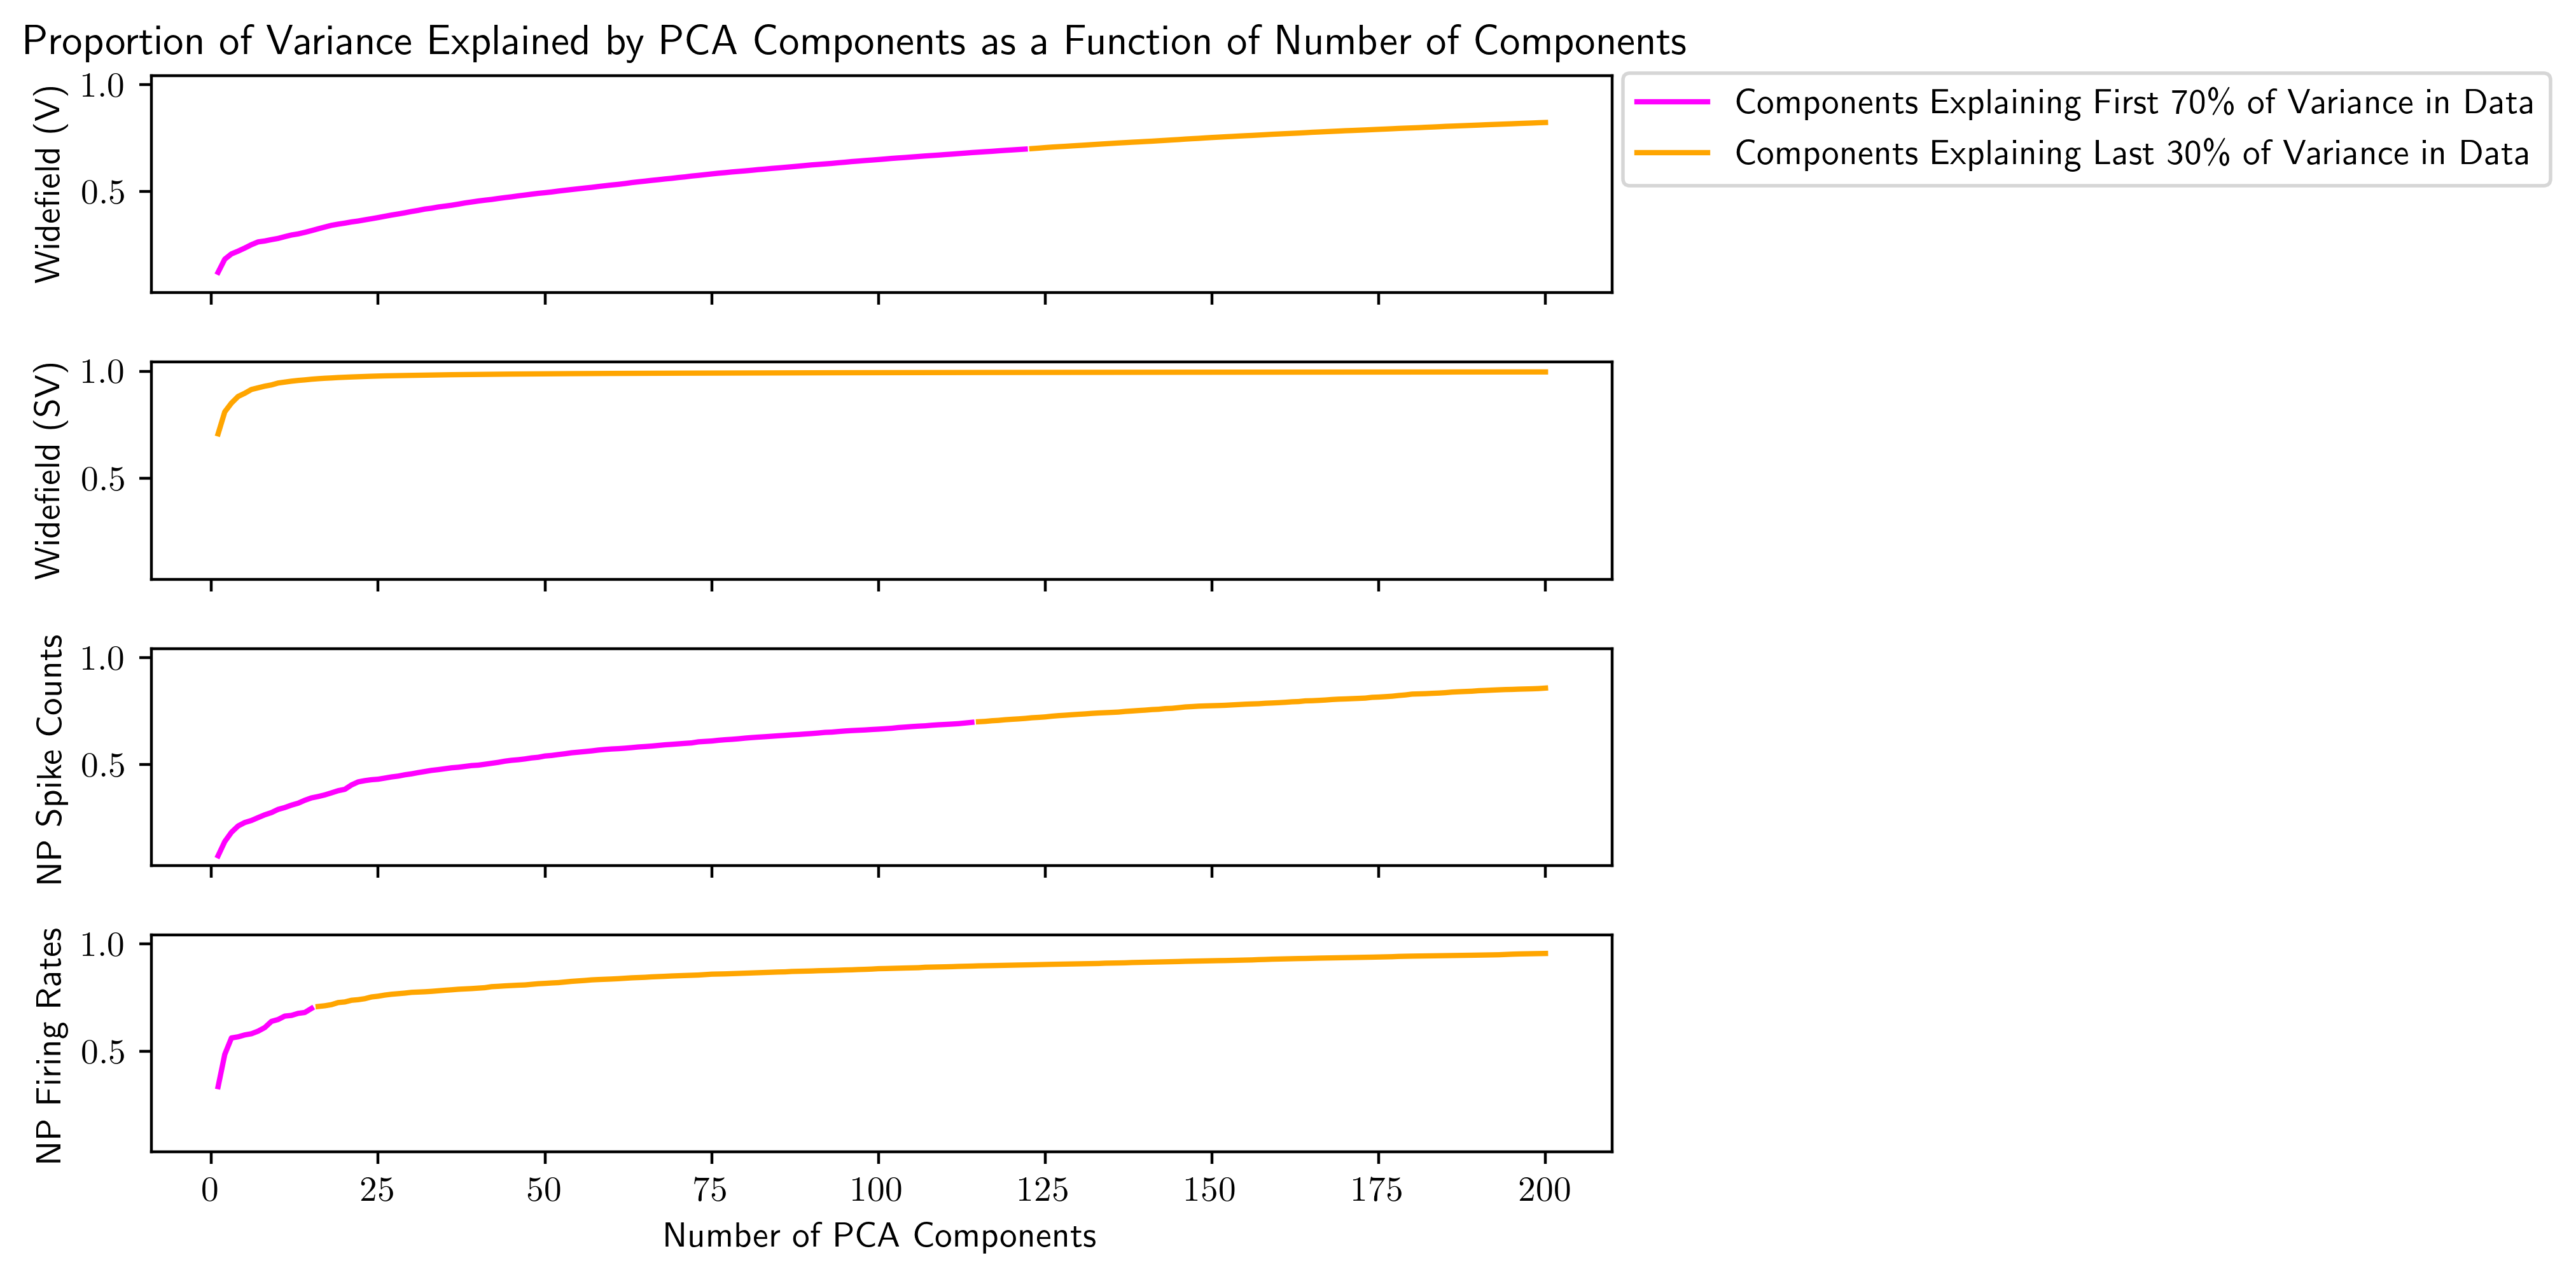

In [8]:
fig,ax = plt.subplots(4,1,sharex=True,sharey=True)
fig.tight_layout()
# Widefield (V)
V_score_first_part = V_scores[V_scores<=0.7]
V_score_second_part = V_scores[V_scores>0.7]
ax[0].plot(np.arange(1,len(V_score_first_part)+1),V_score_first_part,color='magenta',label="Components Explaining First 70\% of Variance in Data")
ax[0].plot(np.arange(1,len(V_score_second_part)+1)+len(V_score_first_part),V_score_second_part,color='orange',
          label="Components Explaining Last 30\% of Variance in Data")
ax[0].set_ylabel("Widefield (V)")
# Widefield (SV)
wf_score_first_part = wf_scores[wf_scores<=0.7]
wf_score_second_part = wf_scores[wf_scores>0.7]
ax[1].plot(np.arange(1,len(wf_score_first_part)+1),wf_score_first_part,color='magenta')
ax[1].plot(np.arange(1,len(wf_score_second_part)+1)+len(wf_score_first_part),wf_score_second_part,color='orange')
ax[1].set_ylabel("Widefield (SV)")
# Neuropixel spike counts
np_score_first_part = np_scores[np_scores<=0.7]
np_score_second_part = np_scores[np_scores>0.7]
ax[2].plot(np.arange(1,len(np_score_first_part)+1),np_score_first_part,color='magenta')
ax[2].plot(np.arange(1,len(np_score_second_part)+1)+len(np_score_first_part),np_score_second_part,color='orange')
ax[2].set_ylabel("NP Spike Counts")
# Neuropixel firing rates
rate_score_first_part = rate_scores[rate_scores<=0.7]
rate_score_second_part = rate_scores[rate_scores>0.7]
ax[3].plot(np.arange(1,len(rate_score_first_part)+1),rate_score_first_part,color='magenta')
ax[3].plot(np.arange(1,len(rate_score_second_part)+1)+len(rate_score_first_part),rate_score_second_part,color='orange')
ax[3].set_xlabel("Number of PCA Components")
ax[3].set_ylabel("NP Firing Rates")
fig.suptitle("Proportion of Variance Explained by PCA Components as a Function of Number of Components",y=1)
fig.legend(bbox_to_anchor=(1.55, 0.975));

Next let's look at the second derivatives of the functions in these plots.

Text(0.5, 1.01, 'Second Derivatives of Explained Variances as Functions of Number of PCA Components')

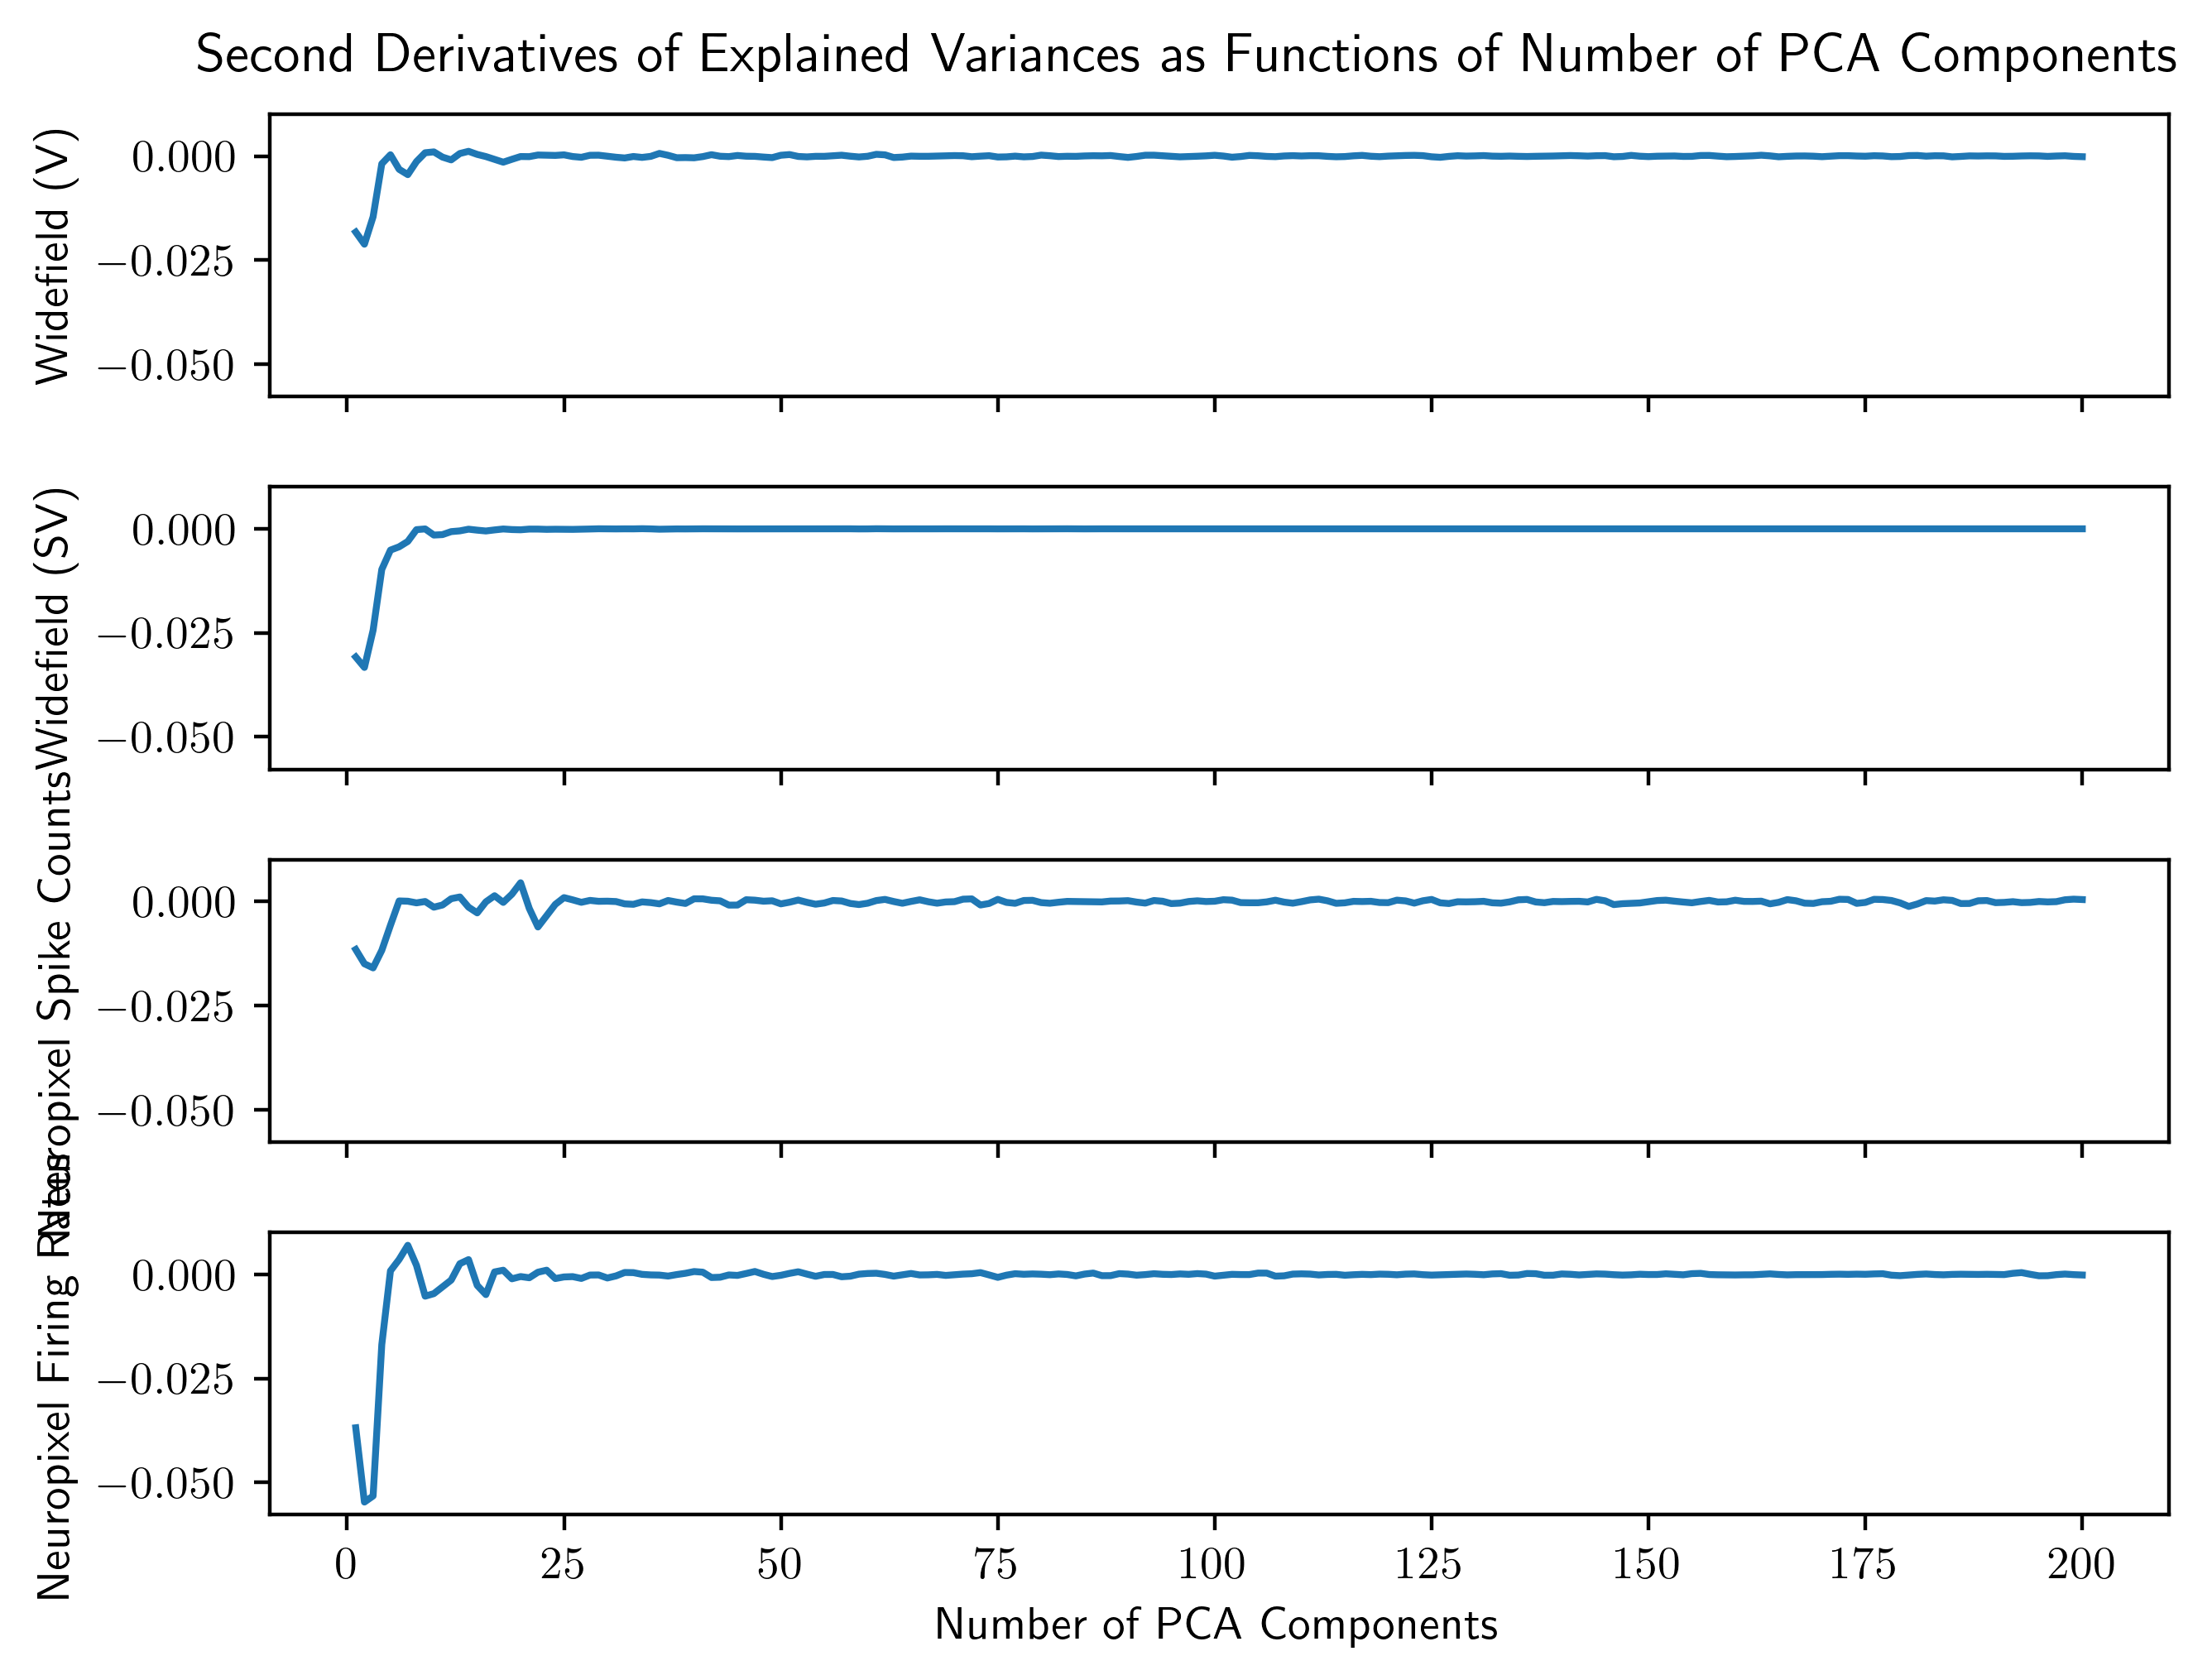

In [121]:
fig,ax = plt.subplots(4,1,sharex=True,sharey=True)
fig.tight_layout()
ax[0].plot(np.arange(1,201),d2dx(V_scores))
ax[0].set_ylabel("Widefield (V)")
ax[1].plot(np.arange(1,201),d2dx(wf_scores))
ax[1].set_ylabel("Widefield (SV)")
ax[2].plot(np.arange(1,201),d2dx(np_scores))
ax[2].set_ylabel("Neuropixel Spike Counts")
ax[3].plot(np.arange(1,201),d2dx(rate_scores))
ax[3].set_ylabel("Neuropixel Firing Rates")
ax[3].set_xlabel("Number of PCA Components")
fig.suptitle("Second Derivatives of Explained Variances as Functions of Number of PCA Components",y=1.01)

Let's look at the number of PCA components from the training data needed to explain >70% of the variance in the test data.

In [9]:
print("Number of Training Components Needed to Explain 70% of the Variance in Each Data Set:")
print("Widefield (V): " + str(len(V_score_first_part)+1))
print("Widefield (SV): " + str(len(wf_score_first_part)+1))
print("Neuropixel Spike Counts: " + str(len(np_score_first_part)+1))
print("Neuropixel Firing Rates: " + str(len(rate_score_first_part)+1))

Number of Training Components Needed to Explain 70% of the Variance in Each Data Set:
Widefield (V): 123
Widefield (SV): 1
Neuropixel Spike Counts: 115
Neuropixel Firing Rates: 16


And then let's look at the when the second derivative of the explained variance goes below threshold for varying thresholds.

In [125]:
latent_dims_pred = pd.DataFrame()
latent_dims_pred['Widefield (V)'] = ([latent_dim(V_scores,0.005),latent_dim(V_scores,0.001),latent_dim(V_scores,0.0005),latent_dim(V_scores,0.0001)])
latent_dims_pred['Widefield (SV)'] = ([latent_dim(wf_scores,0.005),latent_dim(wf_scores,0.001),latent_dim(wf_scores,0.0005),latent_dim(wf_scores,0.0001)])
latent_dims_pred['Neuropixel Spike Counts']=[latent_dim(np_scores,0.005),latent_dim(np_scores,0.001),latent_dim(np_scores,0.0005),latent_dim(np_scores,0.0001)]
latent_dims_pred['Neuropixel Firing Rates'] = ([latent_dim(rate_scores,0.005),latent_dim(rate_scores,0.001),latent_dim(rate_scores,0.0005),latent_dim(rate_scores,0.0001)])
latent_dims_pred.index = ['0.005','0.001','0.0005','0.0001']
latent_dims_pred

,Widefield (V),Widefield (SV),Neuropixel Spike Counts,Neuropixel Firing Rates
0.005,3,5,6,6
0.001,9,9,16,18
0.0005,16,11,47,37
0.0001,103,21,151,116


There are several interesting ideas here. First let's try to explain the plots of variance explained as a function of the number of PCA components. In plot one, we are looking at the variance of the test set explained by the variance in the training set when the training set is the first 90% of the temporal components ($V$ in the SVD $U\Sigma V^T$ of the widefield video) and the test set is the remaining 10%. Whereas in plot two, our training and testing sets are submatrices of $\Sigma V$ rather than $V$. In the second plot, one PCA component from the training PCA is sufficient to explain >70% of the variance in the test set, whereas in plot one it takes 123 PCA components from the training PCA to explain >70% of the variance in the test set. This distinction is presumably because the widefield data is so low dimensional, and hence the first few PCA components in $\Sigma V$ are weighted far more heavily than the others. Therefore, we only need to explain the variance in these first few components to explain most of the variance in the data, and naturally we can explain this variance with a correspondingly small number of PCA components done on the training data. Presumably, the one component needed to explain 70% of the variance in the data is the first, primary component predicting itself. When we remove the information of how much each component should be weighted (going from $\Sigma V$ to $V$) it takes more components from the earlier data to explain the variance in the future data. This is just something to keep in mind when working with this dataset.

Finally, the first few PCA components of the earlier firing rate explain the later data better than the first few PCA components of the spike count data do for the later spike count data. Perhaps the time-window averaging makes the data more Gaussian by something analogous to the central limit theorem, so PCA is better able to find a low dimensional structure. Alternatively, perhaps there are many states that the population of neurons transition between, and the time-window averaging blurs these into one state, producing lower dimensional data.

Next let's focus on the second derivative of the data. Interpreting the number of PCA components before the explained variance function becomes approximately linear as a measure of the dimensionality of the data, we see that the widefield data is lower dimensional than the neuropixel data. I believe 0.001 is a good threshold here, as the dimensionality of the widefield data in this case (9) agrees with the dimensionality I have found through work with BOPDMD and autoencoders, and at 0.0005 the number of components begins to blow up for the neuropixel data. The number of components that the algorithm finds in this prediction case are also similar to those that it finds when we were just looking at the second derivative of the explained variance for PCA on each dataset. Thus, these ~10 latent variables can be found by doing PCA on the whole data set or just the first 90%, and learning them from the first 90% should allow us to predict future data (although we have not done that here).

**Conclusions**

The neuropixel and widefield data sets have low-dimensional latent structure, which we can quantify by doing PCA, plotting the variance explained as a function of the number of components, and asking when the plot becomes approximately linear. The widefield data appears somewhat lower dimensional than the neuropixel data based on this metric. This latent structure can be found by either training on all of the data or only the first 90% of it, and in the latter case explains a large amount of the variance in the last 10% of the data.

PCA finds that the first few PCA components explain almost all of the variance in the case of the widefield data, whereas in the case of neuropixel spike counts, the first few components do not explain that much of the variance. However, time-window averaging can improve this.